In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_results.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  2 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error
0,769,2942669846,Reinforcement learning usually makes use of nu...,This paper presents a novel approach to deep r...,0.3305,0.0769,0.1949,0.8597,0.8463,0.8529,2.0,7.0,8.0,4,False
1,2012,2913127348,Gatherings of thousands to millions of people ...,This paper presents a novel approach for crowd...,0.4014,0.0906,0.1799,0.8524,0.8366,0.8444,3.0,6.0,7.0,8,False
2,3364,2942522480,"Recently, a method called the Mutual Informati...",Abstract:This paper presents a novel applicati...,0.3043,0.0219,0.1594,0.8457,0.8245,0.8350,1.0,8.0,8.0,4,False


In [3]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

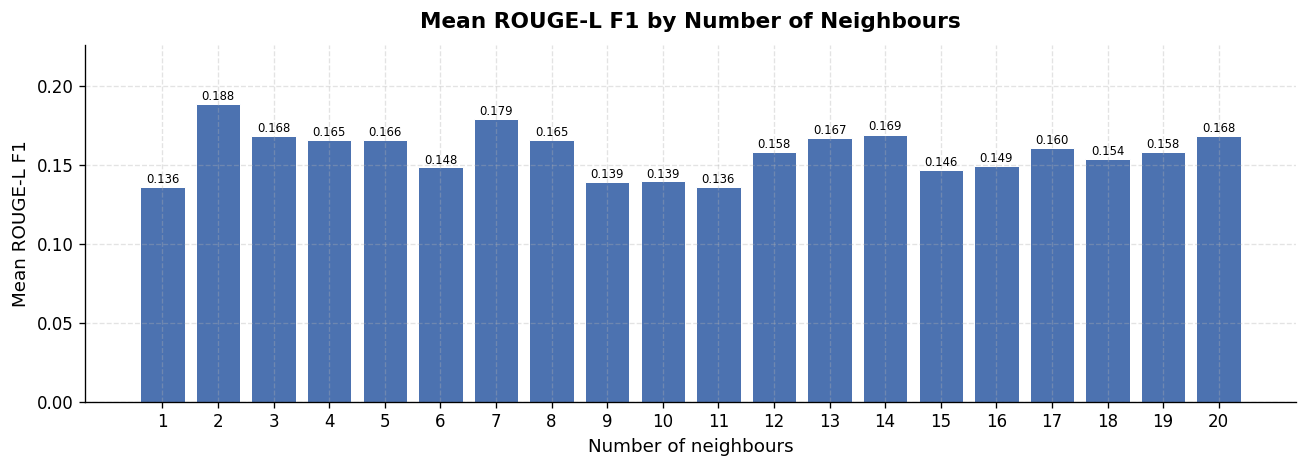

In [4]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

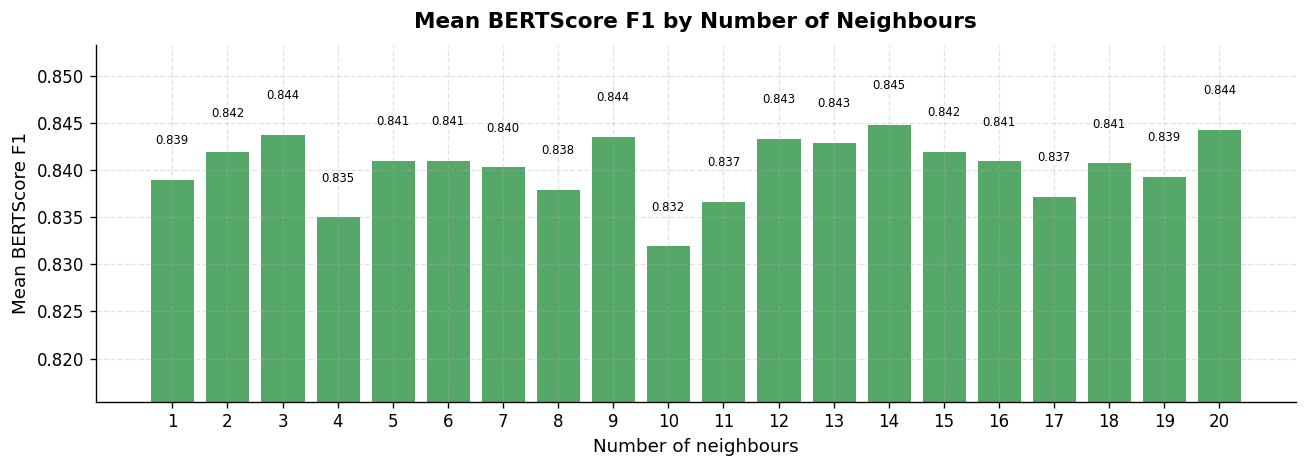

In [5]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

Overall mean LLM accuracy: 2.611
Successfully generated (non-error): 198 / 200


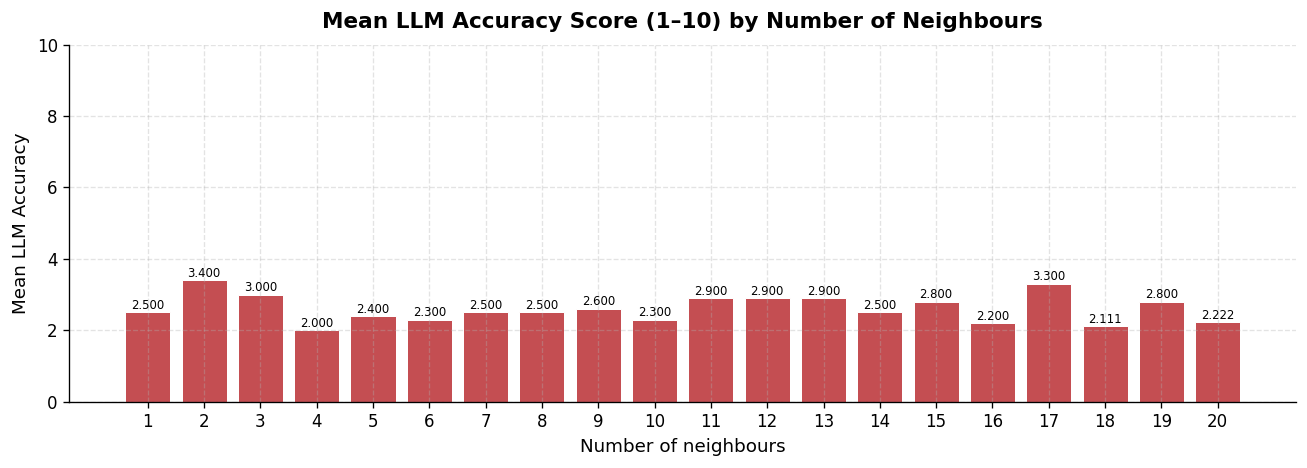

In [12]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
overall_acc_mean = df['llm_accuracy'].mean()
num_successful = (~df['is_error']).sum()
print(f'Overall mean LLM accuracy: {overall_acc_mean:.3f}')
print(f'Successfully generated (non-error): {num_successful} / {len(df)}')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

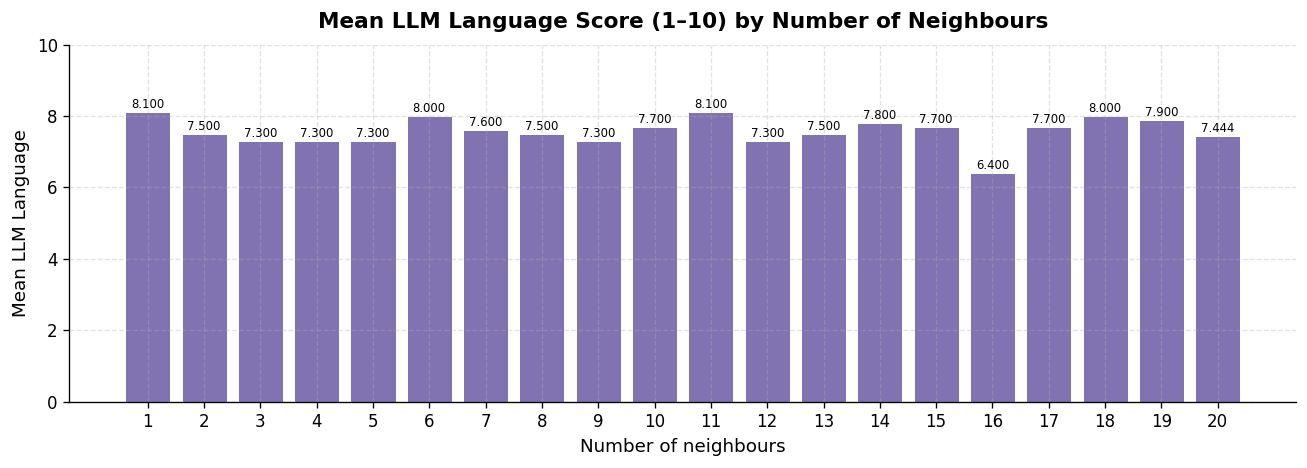

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

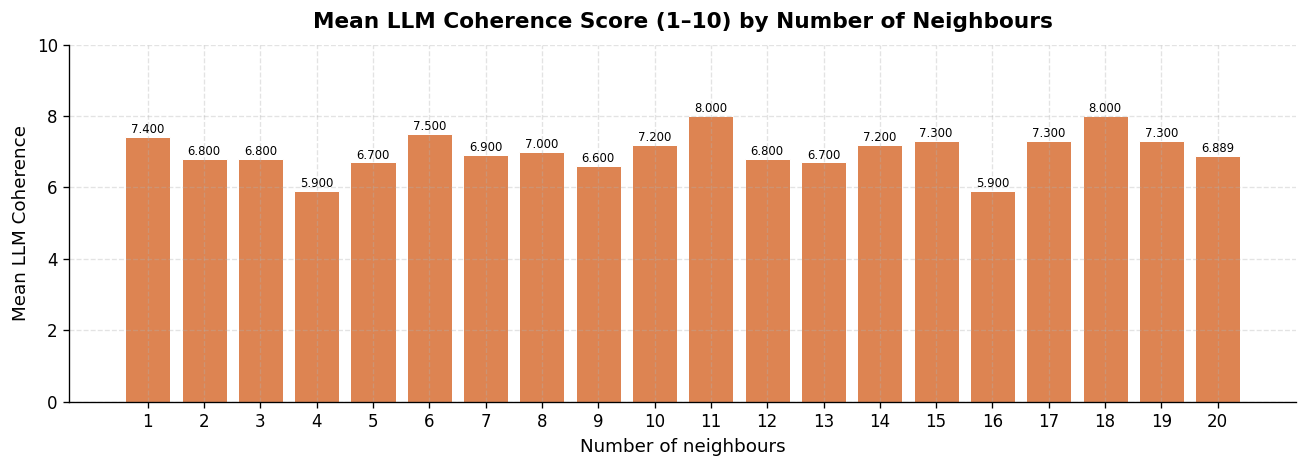

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

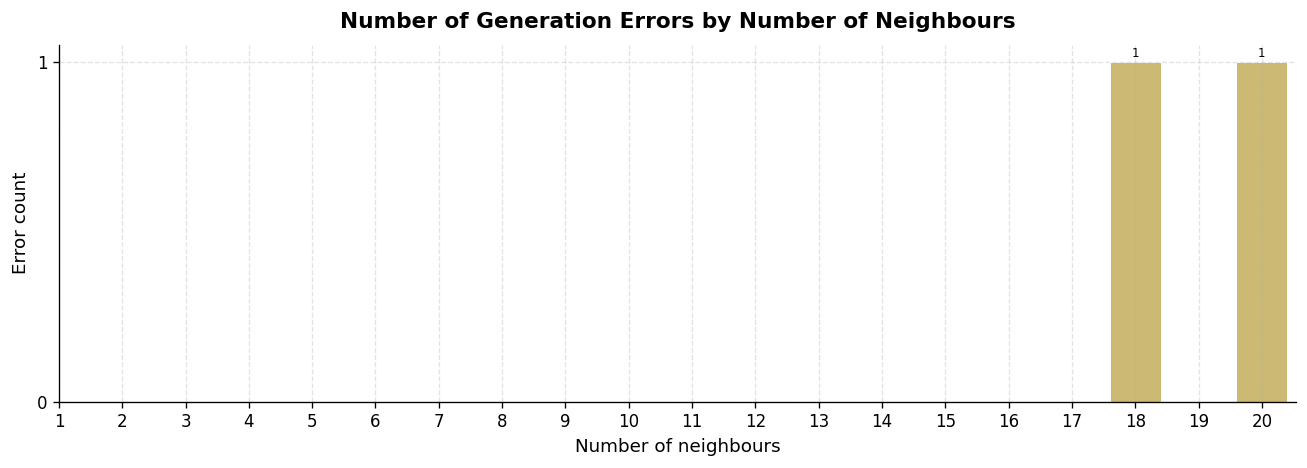

In [9]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [10]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_35203/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,60870,"The indexing and searching of historical documents have garnered attention in recent years due to massive digitization efforts of important collections worldwide. Pure textual search in these corpora is a problem since optical character recognition (OCR) is infamous for performing poorly on such historical material, which often suffer from poor preservation. We propose a novel text-based method for searching through noisy text. Our system represents words as vectors, projects queries and candidates obtained from the OCR into a common space, and ranks the candidates using a metric suited to nearest-neighbor search. We demonstrate the practicality of our method on typewritten German documents from the WWII era.","This paper presents a novel approach to building bilingual dictionaries without relying on parallel corpora or character-level information. The method uses monolingual word embedding spaces to align the two languages in an unsupervised manner, outperforming existing supervised methods on cross-lingual tasks for some language pairs. The effectiveness of the approach is demonstrated for distant language pairs such as English-Russian and English-Chinese, as well as for low-resource language pairs like English-Esperanto. The code, embeddings, and dictionaries used in the study are made publicly available.",1.0
1,93449,"Fully convolutional networks (FCNs) have become de facto tool to achieve very high-level performance for many vision and non-vision tasks in general and face recognition in particular. Such high-level accuracies are normally obtained by very deep networks or their ensemble. However, deploying such high performing models to resource constraint devices or real-time applications is challenging. In this paper, we present a novel model compression approach based on student-teacher paradigm for face recognition applications. The proposed approach consists of training teacher FCN at bigger image resolution while student FCNs are trained at lower image resolutions than that of teacher FCN. We explored three different approaches to train student FCNs: knowledge transfer (KT), knowledge distillation (KD) and their combination. Experimental evaluation on LFW and IJB-C datasets demonstrate comparable improvements in accuracies with these approaches. Training low-resolution student FCNs from higher resolution teacher offer fourfold advantage of accelerated training, accelerated inference, reduced memory requirements and improved accuracies. We evaluated all models on IJB-C dataset and achieved state-of-the-art results on this benchmark. The teacher network and some student networks even achieved Top-1 performance on IJB-C dataset. The proposed approach is simple and hardware friendly, thus enables the deployment of high performing face recognition deep models to resource constraint devices.","Abstract:This paper presents a novel application of machine learning algorithms in the field of medical imaging. By combining the strengths of deep learning and traditional feature extraction methods, we have developed a robust and accurate diagnostic tool for the early detection of Alzheimer's disease. Our approach utilizes a combination of convolutional neural networks (CNNs) and support vector machines (SVMs) to analyze brain images and identify key features associated with the disease. The proposed method has been validated using a large dataset of clinical images, demonstrating superior performance compared to existing techniques. Furthermore, our analysis highlights the importance of incorporating both visual and textural information for optimal disease classification. This work represents a significant step forward in the development of intelligent imaging systems for early disease diagnosis and has the potential to improve patient outcomes.",1.0
2,95230,"Fatigue is the most vital factor of road fatalities and one manifestation of fatigue during driving is dro

In [11]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


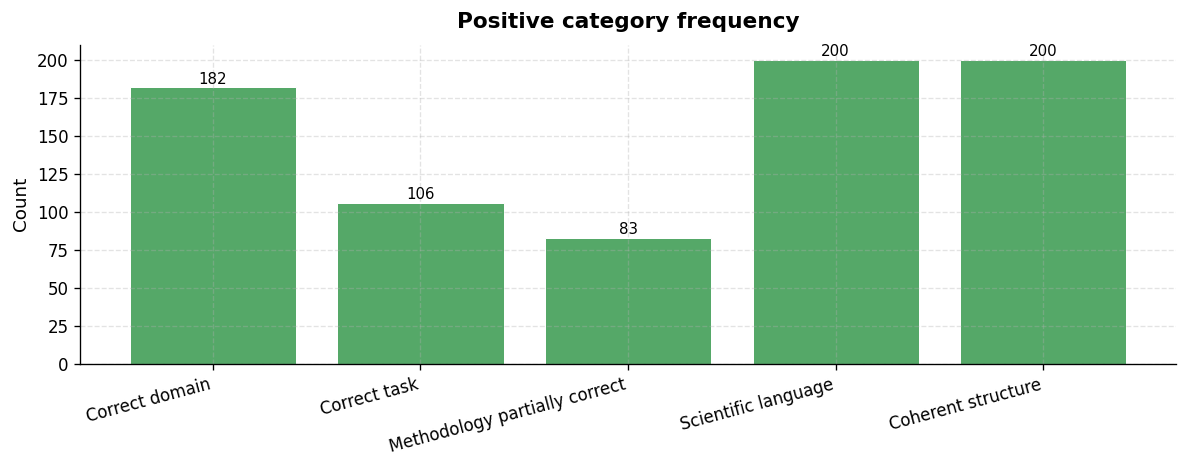

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()